In [1]:
# Now we train the new model using the insights we gained
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression, PoissonRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.feature_selection import r_regression, f_regression, mutual_info_regression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report, precision_recall_curve
import matplotlib.pyplot as plt
import seaborn as sns
from catboost import CatBoostRegressor, CatBoostClassifier
import dill
from sklearn.model_selection import GroupKFold
from sklearn.base import clone
from sklearn.metrics import (
    mean_absolute_error,
    mean_poisson_deviance,
    r2_score,
)
from sklearn.model_selection import GridSearchCV, GroupKFold

In [2]:
df_train_auto_policies = pd.read_csv("../data/train.csv")


df_train_auto_policies["had_claim_binary"] = (df_train_auto_policies["claim_count"] > 0).astype(int)
df_train_auto_policies['avg_loss'] = np.where(
    df_train_auto_policies['had_claim_binary'] == 0, df_train_auto_policies['total_loss_amount'],df_train_auto_policies['total_loss_amount']/df_train_auto_policies['claim_count'])


In [3]:
# Calculate log severity only where a claim has a positive, finite average loss.
claim_severity_mask = (
    df_train_auto_policies['had_claim_binary'].eq(1)
    & df_train_auto_policies['avg_loss'].gt(0)
    & np.isfinite(df_train_auto_policies['avg_loss'])
)

df_train_auto_policies['avg_loss_log'] = np.nan
df_train_auto_policies.loc[claim_severity_mask, 'avg_loss_log'] = np.log(
    df_train_auto_policies.loc[claim_severity_mask, 'avg_loss']
)

valid_log_severity = df_train_auto_policies.loc[claim_severity_mask, 'avg_loss_log']
if valid_log_severity.empty:
    raise ValueError('No positive finite claim severities are available for outlier detection.')

percentile25 = valid_log_severity.quantile(0.25)
percentile75 = valid_log_severity.quantile(0.75)
iqr = percentile75 - percentile25
upper_limit = percentile75 + 1.5 * iqr

outlier_mask = claim_severity_mask & df_train_auto_policies['avg_loss_log'].gt(upper_limit)

print('Log-severity lower quartile:', percentile25)
print('Log-severity upper quartile:', percentile75)
print('Log-severity IQR:', iqr)
print('Upper outlier limit:', upper_limit)
print('Claim policies with valid severity:', int(claim_severity_mask.sum()))
print('Claim policies excluded for nonpositive or missing severity:', int((df_train_auto_policies['had_claim_binary'].eq(1) & ~claim_severity_mask).sum()))
print('Upper outliers removed:', int(outlier_mask.sum()))

# Keep claim policies with valid severity after removing upper IQR outliers.
df_claims = df_train_auto_policies.loc[claim_severity_mask & ~outlier_mask].copy()

Log-severity lower quartile: 8.131610119216012
Log-severity upper quartile: 10.753096668484686
Log-severity IQR: 2.621486549268674
Upper outlier limit: 14.685326492387697
Claim policies with valid severity: 1861
Claim policies excluded for nonpositive or missing severity: 0
Upper outliers removed: 2


In [4]:
df_train_auto_policies

,policy_id,insured_id,snapshot_date,policy_effective_date,policy_expiration_date,coverage_type,vehicle_count,vehicle_avg_age,driver_count,driver_avg_age,...,late_payment_count,claim_count,total_loss_amount,first_claim_reported_date,claim_paid_amount_current_period,claim_status_current_period,days_to_first_claim_report,had_claim_binary,avg_loss,avg_loss_log
0,POL-006680,INS-00529,2021-07-24,2021-05-26,2022-05-26,APD,7,5.9,8,47.5,...,1.0,0,0.0,NaN,0.00,No Claim,NaN,0,0.0,NaN
1,POL-003291,INS-02313,2021-03-17,2020-11-26,2021-11-26,APD,6,6.0,6,32.5,...,3.0,0,0.0,NaN,0.00,No Claim,NaN,0,0.0,NaN
2,POL-006559,INS-02723,2022-11-10,2022-05-17,2023-05-17,APD,6,4.1,5,40.9,...,0.0,0,0.0,NaN,0.00,No Claim,NaN,0,0.0,NaN
3,POL-007927,INS-03739,2021-03-12,2020-10-20,2021-10-20,AL,14,6.0,9,47.5,...,0.0,0,0.0,NaN,0.00,No Claim,NaN,0,0.0,NaN
4,POL-005665,INS-00218,2021-08-21,2021-05-04,2022-05-04,APD,7,2.5,2,48.1,...,0.0,0,0.0,NaN,0.00,No Claim,NaN,0,0.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15070,POL-005192,INS-00229,2022-09-27,2022-06-05,2023-06-05,APD,9,4.0,7,39.2,...,0.0,0,0.0,NaN,0.00,No Claim,NaN,0,0.0,NaN
15071,POL-013419,INS-03560,2021-10-06,2021-09-14,2022-09-14,AL,8,0.3,9,38.9,...,3.0,0,0.0,NaN,0.00,No Claim,NaN,0,0.0,NaN
15072,POL-005391,INS-02372,2020-07-15,2020-07-12,2021-07-12,APD,9,5.8,6,44.2,...,3.0,1,2319.7,2020-09-09,1773.08,Under Review,56.0,1,2319.7,7.749193
15073,POL-000861,INS-02516,2022-11-26,2022-10-24,2023-10-24,APD,6,2.8,6,23.2,...,2.0,0,0.0,NaN,0.00,No Claim,NaN,0,0.0,NaN


In [5]:
#We load our predefined prep pipelines

with open('pipeline_prep_lg_v2.dill', 'rb') as f:
    loaded_cleaning_pipe_lg_v2 = dill.load(f)

with open('pipeline_prep_catboost_v2.dill', 'rb') as f:
    loaded_cleaning_pipe_cat_v2 = dill.load(f)

loaded_cleaning_pipe_lg_v2.set_output(transform="pandas")
loaded_cleaning_pipe_cat_v2.set_output(transform="pandas")

,steps,"[('preprocessor_catboost', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('coverage_preprocessor', ...), ('btype_preprocessor', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [6]:


feat_cols = [
    "coverage_type",
    "vehicle_count", "vehicle_avg_age", "driver_count", "driver_avg_age",
    "years_in_business", "prior_year_mileage_000",
    "business_type", "state",
    "prior_apd_claim_count", "prior_al_claim_count", "prior_loss_amount", "num_heavy_vehicles"
]
target_log_r = ["had_claim_binary"]
target_cat_claims = ["claim_count"]
target_cat_loss = ["avg_loss"]

In [7]:
data_claim_count = df_train_auto_policies.drop_duplicates(subset="policy_id").reset_index(drop=True)

data_claim_count = data_claim_count[data_claim_count['had_claim_binary'] == 1]

X = data_claim_count[feat_cols]
y = data_claim_count["claim_count"]
groups = data_claim_count["insured_id"]

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))

X_train_claim_count = X.iloc[train_idx]
X_test_claim_count = X.iloc[test_idx]
y_train_claim_count = y.iloc[train_idx]
y_test_claim_count = y.iloc[test_idx]

assert set(groups.iloc[train_idx]).isdisjoint(set(groups.iloc[test_idx]))

In [8]:
full_production_pipeline_claimCount_poisson = Pipeline([
    ('data_prep', loaded_cleaning_pipe_lg_v2),
    ('regressor', PoissonRegressor(alpha=1e-4, max_iter=1000))      
])

full_production_pipeline_claimCount_poisson.fit(X_train_claim_count,y_train_claim_count)

,steps,"[('data_prep', ...), ('regressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,steps,"[('preprocessor_logr', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('coverage_preprocessor', ...), ('btype_preprocessor', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3


In [9]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
claimCount_Xtest = full_production_pipeline_claimCount_poisson.predict(X_test_claim_count)
print("RMSE:", np.sqrt(mean_squared_error(y_test_claim_count, claimCount_Xtest)))
print("MAE:", mean_absolute_error(y_test_claim_count, claimCount_Xtest))
print("R2 Score:", r2_score(y_test_claim_count, claimCount_Xtest))

RMSE: 0.5255894540073072
MAE: 0.2713472656770006
R2 Score: 0.05758276514130689


In [10]:
data_claim_bin = df_train_auto_policies.drop_duplicates(subset="policy_id").reset_index(drop=True)

X = data_claim_bin[feat_cols]
y = data_claim_bin["had_claim_binary"]
groups = data_claim_bin["insured_id"]

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx_had, test_idx_had = next(splitter.split(X, y, groups=groups))

X_train_claim_had = X.iloc[train_idx_had]
X_test_claim_had = X.iloc[test_idx_had]
y_train_claim_had = y.iloc[train_idx_had]
y_test_claim_had = y.iloc[test_idx_had]

assert set(groups.iloc[train_idx_had]).isdisjoint(set(groups.iloc[test_idx_had]))

In [11]:
full_production_pipeline_hadClaim_log = Pipeline([
    ('data_prep', loaded_cleaning_pipe_lg_v2),
    ('model', LogisticRegression(
              class_weight={0: 1, 1:7},   max_iter=1000))       
])

full_production_pipeline_hadClaim_log.fit(X_train_claim_had,y_train_claim_had)

,steps,"[('data_prep', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,steps,"[('preprocessor_logr', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('coverage_preprocessor', ...), ('btype_preprocessor', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3


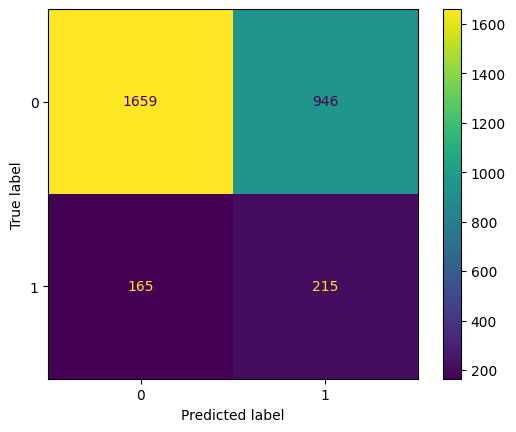

In [12]:
hadClaim_Xtest = full_production_pipeline_hadClaim_log.predict(X_test_claim_had)
c_matrix = confusion_matrix(y_test_claim_had, hadClaim_Xtest)
disp = ConfusionMatrixDisplay(confusion_matrix = c_matrix)
disp.plot()
plt.show()

In [13]:
print(classification_report(y_test_claim_had, hadClaim_Xtest))

              precision    recall  f1-score   support

           0       0.91      0.64      0.75      2605
           1       0.19      0.57      0.28       380

    accuracy                           0.63      2985
   macro avg       0.55      0.60      0.51      2985
weighted avg       0.82      0.63      0.69      2985



In [14]:
from sklearn.svm import SVC

svc_pipeline = Pipeline([
    ('data_prep', loaded_cleaning_pipe_lg_v2),
    ('model', SVC(kernel='rbf', class_weight='balanced')),
])

svc_search = GridSearchCV(
    estimator=svc_pipeline,
    param_grid={
        'model__C': [0.1, 1, 10],
        'model__gamma': ['scale', 'auto'],
    },
    scoring={
        'average_precision': 'average_precision',
        'precision': 'precision',
        'recall': 'recall',
    },
    refit='average_precision',
    cv=GroupKFold(n_splits=3),
    n_jobs=-1,
)

svc_search.fit(
    X_train_claim_had,
    y_train_claim_had,
    groups=groups.iloc[train_idx_had],
)

full_production_pipeline_hadClaim_svc = svc_search.best_estimator_
print('Best SVC parameters:', svc_search.best_params_)
print('Best grouped CV average precision:', svc_search.best_score_)

Best SVC parameters: {'model__C': 0.1, 'model__gamma': 'auto'}
Best grouped CV average precision: 0.1876016475551574


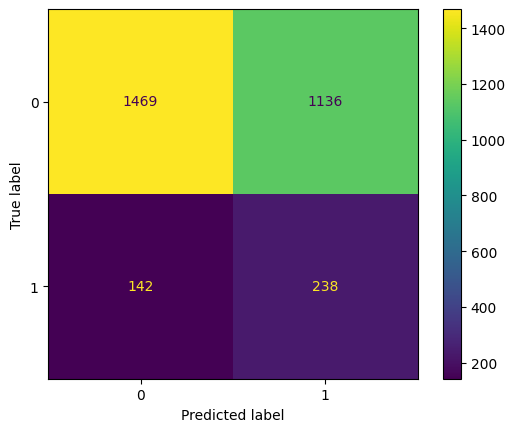

              precision    recall  f1-score   support

           0       0.91      0.56      0.70      2605
           1       0.17      0.63      0.27       380

    accuracy                           0.57      2985
   macro avg       0.54      0.60      0.48      2985
weighted avg       0.82      0.57      0.64      2985



In [15]:
hadClaim_Xtest_svc = full_production_pipeline_hadClaim_svc.predict(X_test_claim_had)
c_matrix_svc = confusion_matrix(y_test_claim_had, hadClaim_Xtest_svc, labels=[0, 1])
disp_svc = ConfusionMatrixDisplay(confusion_matrix=c_matrix_svc)
disp_svc.plot()
plt.show()
print(classification_report(y_test_claim_had, hadClaim_Xtest_svc, zero_division=0))

In [16]:
print(classification_report(y_test_claim_had, hadClaim_Xtest_svc))

              precision    recall  f1-score   support

           0       0.91      0.56      0.70      2605
           1       0.17      0.63      0.27       380

    accuracy                           0.57      2985
   macro avg       0.54      0.60      0.48      2985
weighted avg       0.82      0.57      0.64      2985



In [17]:
data_avg_loss = df_train_auto_policies.drop_duplicates(subset="policy_id").reset_index(drop=True)

data_avg_loss = data_avg_loss[data_avg_loss['had_claim_binary'] == 1]

X = data_avg_loss[feat_cols]
y = data_avg_loss["avg_loss"]
groups = data_avg_loss["insured_id"]

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx_tl, test_idx_tl = next(splitter.split(X, y, groups=groups))

X_train_tl = X.iloc[train_idx_tl].copy()
X_test_tl = X.iloc[test_idx_tl].copy()
y_train_tl = y.iloc[train_idx_tl].copy()
y_test_tl = y.iloc[test_idx_tl].copy()

assert set(groups.iloc[train_idx_tl]).isdisjoint(set(groups.iloc[test_idx_tl]))

train_log_severity = np.log(y_train_tl.where(y_train_tl > 0).dropna())
q1_train = train_log_severity.quantile(0.25)
q3_train = train_log_severity.quantile(0.75)
iqr_train = q3_train - q1_train
upper_limit_train = q3_train + 1.5 * iqr_train

keep_train_mask = (
    y_train_tl.gt(0)
    & np.isfinite(y_train_tl)
    & np.log(y_train_tl).le(upper_limit_train)
)
removed_train_outliers = int((~keep_train_mask).sum())
X_train_tl = X_train_tl.loc[keep_train_mask]
y_train_tl = y_train_tl.loc[keep_train_mask]

print('Training-only upper log-severity limit:', upper_limit_train)
print('Training outliers removed:', removed_train_outliers)
print('Test claims retained, including extreme severities:', len(y_test_tl))

Training-only upper log-severity limit: 14.73681375649269
Training outliers removed: 2
Test claims retained, including extreme severities: 359


In [18]:
full_production_pipeline_avgLoss_cat = Pipeline([
    ('data_prep', loaded_cleaning_pipe_cat_v2),
    ('model', CatBoostRegressor(
       iterations=100,
       learning_rate=0.1,
       loss_function="RMSE",
       eval_metric="MAE",
       cat_features=[
           'coverage_preprocessor__coverage_type',
           'btype_preprocessor__business_type',
           'state_preprocessor__state',
       ],
       verbose=False,
    )),
])

full_production_pipeline_avgLoss_cat.fit(X_train_tl, y_train_tl)

,steps,"[('data_prep', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,steps,"[('preprocessor_catboost', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('coverage_preprocessor', ...), ('btype_preprocessor', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3


In [19]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
avgLoss_Xtest = full_production_pipeline_avgLoss_cat.predict(X_test_tl)
print("RMSE:", np.sqrt(mean_squared_error(y_test_tl, avgLoss_Xtest)))
print("MAE:", mean_absolute_error(y_test_tl, avgLoss_Xtest))
print("R2 Score:", r2_score(y_test_tl, avgLoss_Xtest))

RMSE: 140848.75186634538
MAE: 58552.35772677662
R2 Score: 0.1231837991364636


In [20]:
from risk_scorer_runtime import PolicyRiskScorer

In [21]:
scorer = PolicyRiskScorer(
    full_production_pipeline_hadClaim_log,
    full_production_pipeline_claimCount_poisson,
    full_production_pipeline_avgLoss_cat,
    feat_cols,
)

with open("risk_scorer_deploy.dill", "wb") as file:
    dill.dump(scorer, file)

scorer_check = scorer.predict(X_test_claim_had.head(5))